In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Hello Ranjitha!")
print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)
print("Setup Successful!")

Hello Ranjitha!
Pandas Version: 2.3.3
NumPy Version: 2.3.5
Setup Successful!


In [2]:
!pip install seaborn plotly openpyxl

# Brazilian E-Commerce Analysis (Olist)

## Business Understanding

### About the Company

Olist is a Brazilian e-commerce platform that connects customers with multiple sellers. It manages orders, payments, deliveries, customer reviews, and seller operations.

### Business Problem

The company wants to analyze its sales performance, customer behavior, seller performance, payment methods, and delivery efficiency to improve business decisions.

### Project Objectives

- Analyze sales performance
- Understand customer purchasing behavior
- Identify top-performing products and sellers
- Analyze delivery times
- Study customer reviews
- Build an interactive Power BI dashboard

### Stakeholders

- CEO
- Sales Team
- Marketing Team
- Operations Team
- Product Managers

In [3]:
import pandas as pd
import os

In [4]:
data_path = "../data/raw"

In [5]:
import os
os.getcwd()

'c:\\Users\\ranji\\OneDrive\\Documents\\Olist_Data_Analytics_Project'

In [6]:
data_path = "data/raw"

In [7]:
import os

os.listdir(data_path)

['olist_customers_dataset.csv',
 'olist_geolocation_dataset.csv',
 'olist_orders_dataset.csv',
 'olist_order_items_dataset.csv',
 'olist_order_payments_dataset.csv',
 'olist_order_reviews_dataset.csv',
 'olist_products_dataset.csv',
 'olist_sellers_dataset.csv',
 'product_category_name_translation.csv']

In [8]:
import pandas as pd

orders = pd.read_csv("data/raw/olist_orders_dataset.csv")

In [9]:
import os

print("Current folder:", os.getcwd())
print("\nFiles and folders in the project:")
print(os.listdir())

Current folder: c:\Users\ranji\OneDrive\Documents\Olist_Data_Analytics_Project

Files and folders in the project:
['.ipynb_checkpoints', '01_Business_Understanding.ipynb', 'anaconda_projects', 'data', 'images', 'notebooks', 'olist.db', 'powerbi', 'README.txt', 'reports', 'requirements.txt', 'sql']


In [10]:
print(os.listdir("data"))

['cleaned', 'raw']


In [11]:
print(os.listdir("data/raw"))

['olist_customers_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_orders_dataset.csv', 'olist_order_items_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_products_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv']


In [12]:
import pandas as pd

orders = pd.read_csv("data/raw/olist_orders_dataset.csv")

In [13]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [14]:
orders.shape

(99441, 8)

In [15]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [16]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='object')

Here's how the main tables relate:

Customers ─────┐
               │
Orders ────────┼──── Order Items ───── Products
               │
               ├──── Payments
               │
               ├──── Reviews
               │
               └──── Sellers

# Data Understanding

## Checking Missing Values

In [17]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [18]:
orders.duplicated().sum()

np.int64(0)

In [19]:
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

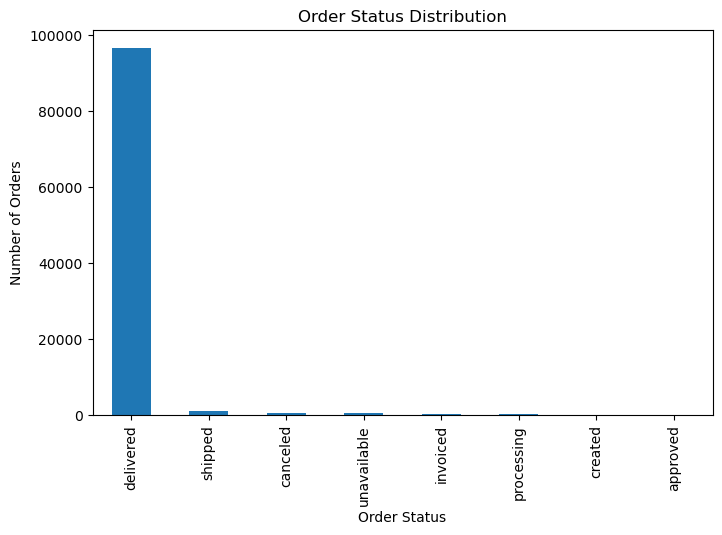

In [20]:
import matplotlib.pyplot as plt

orders["order_status"].value_counts().plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.show()

# Data Cleaning

## Missing Value Analysis

In [21]:
missing_values = orders.isnull().sum()

missing_percentage = (missing_values / len(orders)) * 100

missing_df = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage": missing_percentage
})

missing_df

,Missing Values,Percentage
order_id,0,0.000000
customer_id,0,0.000000
order_status,0,0.000000
order_purchase_timestamp,0,0.000000
order_approved_at,160,0.160899
order_delivered_carrier_date,1783,1.793023
order_delivered_customer_date,2965,2.981668
order_estimated_delivery_date,0,0.000000


In [22]:
orders.nunique()

order_id                         99441
customer_id                      99441
order_status                         8
order_purchase_timestamp         98875
order_approved_at                90733
order_delivered_carrier_date     81018
order_delivered_customer_date    95664
order_estimated_delivery_date      459
dtype: int64

In [23]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col])

In [24]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.1+ MB


In [25]:
orders["purchase_year"] = orders["order_purchase_timestamp"].dt.year
orders["purchase_month"] = orders["order_purchase_timestamp"].dt.month
orders["purchase_day"] = orders["order_purchase_timestamp"].dt.day
orders["purchase_weekday"] = orders["order_purchase_timestamp"].dt.day_name()

In [26]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_year,purchase_month,purchase_day,purchase_weekday
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,2,Monday
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018,7,24,Tuesday
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018,8,8,Wednesday
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017,11,18,Saturday
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018,2,13,Tuesday


In [27]:
orders.to_csv("data/cleaned/orders_cleaned.csv", index=False)

In [28]:
import os
os.listdir("data/cleaned")

['orders_cleaned.csv']

In [29]:
orders["purchase_year"] = orders["order_purchase_timestamp"].dt.year
orders["purchase_month"] = orders["order_purchase_timestamp"].dt.month
orders["purchase_day"] = orders["order_purchase_timestamp"].dt.day
orders["purchase_weekday"] = orders["order_purchase_timestamp"].dt.day_name()

In [30]:
orders[[
    "order_purchase_timestamp",
    "purchase_year",
    "purchase_month",
    "purchase_day",
    "purchase_weekday"
]].head()

,order_purchase_timestamp,purchase_year,purchase_month,purchase_day,purchase_weekday
0,2017-10-02 10:56:33,2017,10,2,Monday
1,2018-07-24 20:41:37,2018,7,24,Tuesday
2,2018-08-08 08:38:49,2018,8,8,Wednesday
3,2017-11-18 19:28:06,2017,11,18,Saturday
4,2018-02-13 21:18:39,2018,2,13,Tuesday


In [31]:
orders.to_csv("data/cleaned/orders_cleaned.csv", index=False)

In [32]:
import os

os.listdir("data/cleaned")

['orders_cleaned.csv']

In [33]:
monthly_orders = (
    orders.groupby("purchase_month")
          .size()
          .reset_index(name="Total Orders")
)

monthly_orders

,purchase_month,Total Orders
0,1,8069
1,2,8508
2,3,9893
3,4,9343
4,5,10573
5,6,9412
6,7,10318
7,8,10843
8,9,4305
9,10,4959


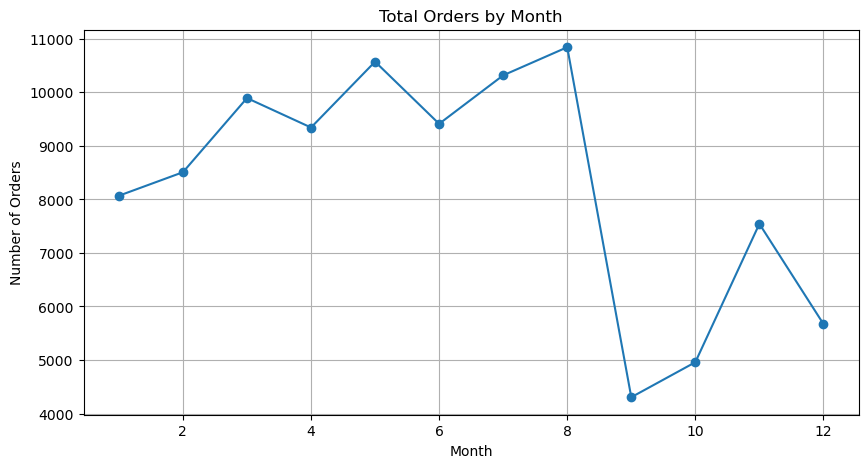

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(
    monthly_orders["purchase_month"],
    monthly_orders["Total Orders"],
    marker="o"
)

plt.title("Total Orders by Month")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.grid(True)

plt.show()

# Understanding the Graph

Your graph answers the business question:

How many orders were placed in each month?

### What we observe
📈 Orders gradually increase from January to August.
🏆 August has the highest number of orders (around 10,900).
📉 September shows a sharp drop.
📈 Orders recover slightly in October and November.

## One Important Point

Notice that you grouped only by month.

Since the data spans 2016–2018, January includes January from multiple years.

## A Better Analysis

Instead of only grouping by month, let's analyze orders by year and month.

In [35]:
orders["purchase_year_month"] = (
    orders["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

In [36]:
monthly_trend = (
    orders.groupby("purchase_year_month")
          .size()
          .reset_index(name="Total Orders")
)

monthly_trend.head()

,purchase_year_month,Total Orders
0,2016-09,4
1,2016-10,324
2,2016-12,1
3,2017-01,800
4,2017-02,1780


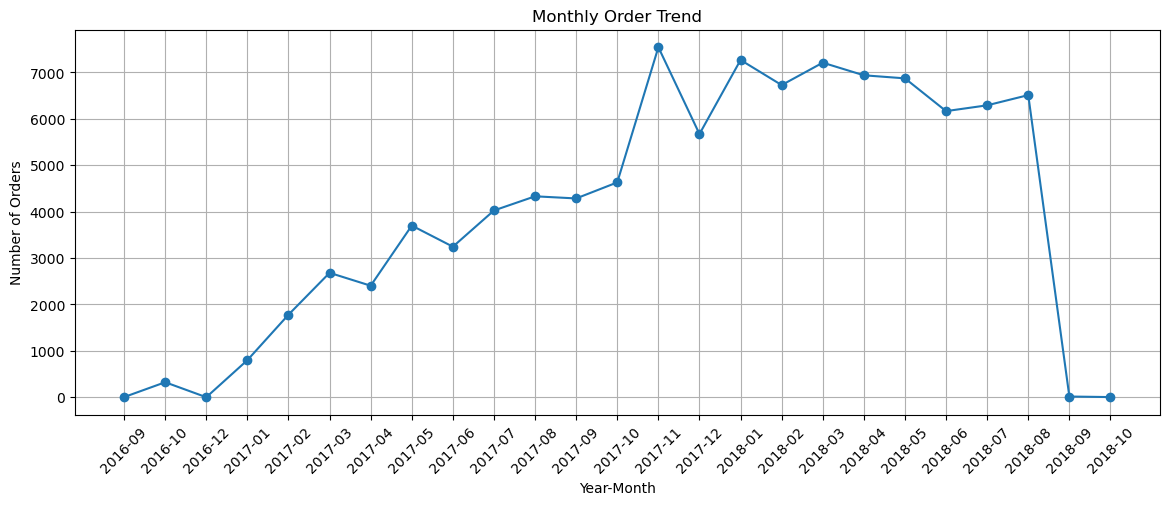

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,5))

plt.plot(
    monthly_trend["purchase_year_month"],
    monthly_trend["Total Orders"],
    marker="o"
)

plt.title("Monthly Order Trend")
plt.xlabel("Year-Month")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)

plt.grid(True)

plt.show()

In [38]:
customers = pd.read_csv("data/raw/olist_customers_dataset.csv")

In [39]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [40]:
customers.shape

(99441, 5)

In [41]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [42]:
customers.describe(include="all")

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
count,99441,99441,99441.000000,99441,99441
unique,99441,96096,NaN,4119,27
top,06b8999e2fba1a1fbc88172c00ba8bc7,8d50f5eadf50201ccdcedfb9e2ac8455,NaN,sao paulo,SP
freq,1,17,NaN,15540,41746
mean,NaN,NaN,35137.474583,NaN,NaN
std,NaN,NaN,29797.938996,NaN,NaN
min,NaN,NaN,1003.000000,NaN,NaN
25%,NaN,NaN,11347.000000,NaN,NaN
50%,NaN,NaN,24416.000000,NaN,NaN
75%,NaN,NaN,58900.000000,NaN,NaN


In [43]:
customers.isnull().sum()

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [44]:
customers.nunique()

customer_id                 99441
customer_unique_id          96096
customer_zip_code_prefix    14994
customer_city                4119
customer_state                 27
dtype: int64

In [45]:
customers = pd.read_csv("data/raw/olist_customers_dataset.csv")

In [46]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [47]:
customers.shape

(99441, 5)

In [48]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [49]:
customers.isnull().sum()

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [50]:
customers.nunique()

customer_id                 99441
customer_unique_id          96096
customer_zip_code_prefix    14994
customer_city                4119
customer_state                 27
dtype: int64

In [51]:
customers["customer_state"].value_counts().head(10)

customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
Name: count, dtype: int64

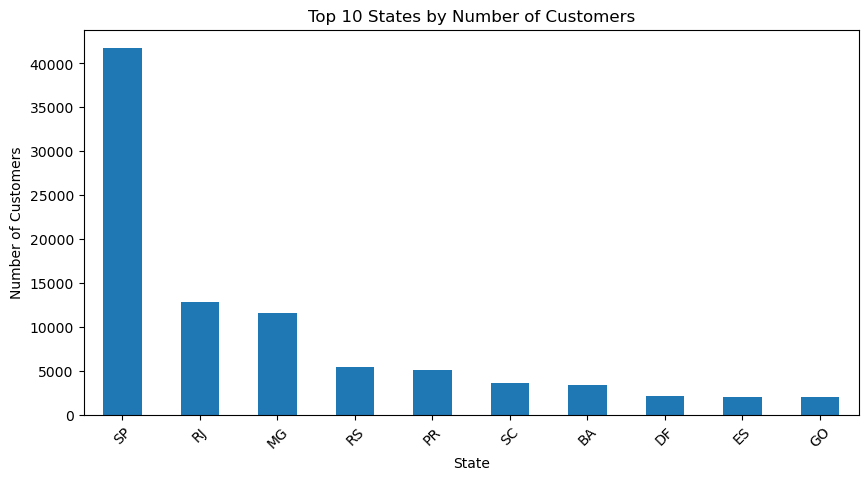

In [52]:
import matplotlib.pyplot as plt

customers["customer_state"].value_counts().head(10).plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("Top 10 States by Number of Customers")
plt.xlabel("State")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.show()

# Combining Multiple Tables

In [53]:
orders_customers = pd.merge(
    orders,
    customers,
    on="customer_id",
    how="inner"
)

In [54]:
orders_customers.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_year,purchase_month,purchase_day,purchase_weekday,purchase_year_month,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,2,Monday,2017-10,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018,7,24,Tuesday,2018-07,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018,8,8,Wednesday,2018-08,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017,11,18,Saturday,2017-11,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018,2,13,Tuesday,2018-02,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP


In [55]:
orders_customers.shape

(99441, 17)

In [56]:
orders_customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 17 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
 8   purchase_year                  99441 non-null  int32         
 9   purchase_month                 99441 non-null  int32         
 10  purchase_day                   99441 non-null  int32         
 11  purchase_weekda

In [57]:
state_orders = (
    orders_customers.groupby("customer_state")
    .size()
    .reset_index(name="Total Orders")
    .sort_values(by="Total Orders", ascending=False)
)

state_orders

,customer_state,Total Orders
25,SP,41746
18,RJ,12852
10,MG,11635
22,RS,5466
17,PR,5045
23,SC,3637
4,BA,3380
6,DF,2140
7,ES,2033
8,GO,2020


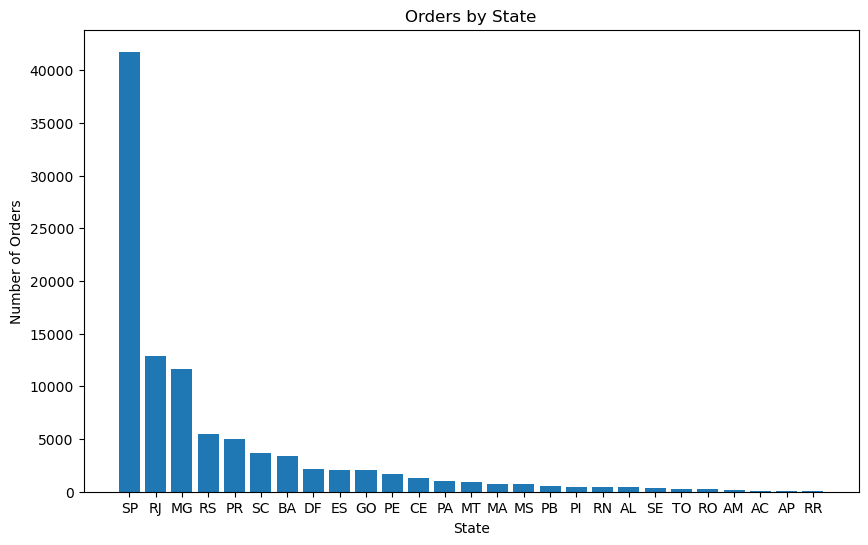

In [58]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.bar(
    state_orders["customer_state"],
    state_orders["Total Orders"]
)

plt.title("Orders by State")
plt.xlabel("State")
plt.ylabel("Number of Orders")

plt.show()

In [59]:
order_items = pd.read_csv("data/raw/olist_order_items_dataset.csv")

In [60]:
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [61]:
order_items.shape

(112650, 7)

In [62]:
order_items.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [63]:
order_items.isnull().sum()

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

In [64]:
order_items.nunique()

order_id               98666
order_item_id             21
product_id             32951
seller_id               3095
shipping_limit_date    93318
price                   5968
freight_value           6999
dtype: int64

In [65]:
order_items[["price", "freight_value"]].describe()

,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


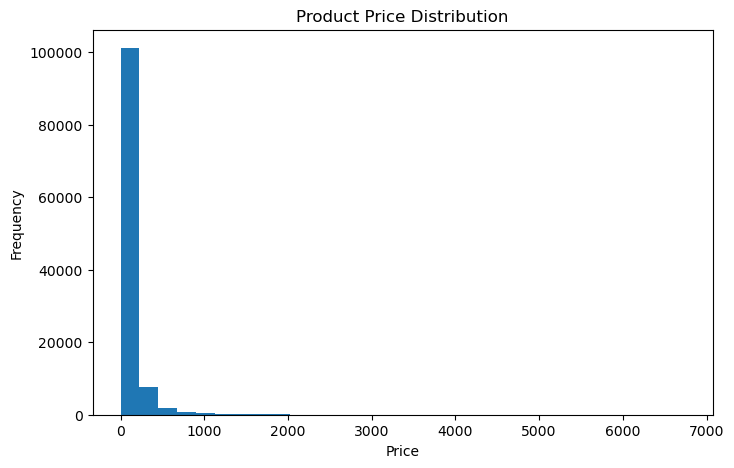

In [66]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(order_items["price"], bins=30)

plt.title("Product Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.show()

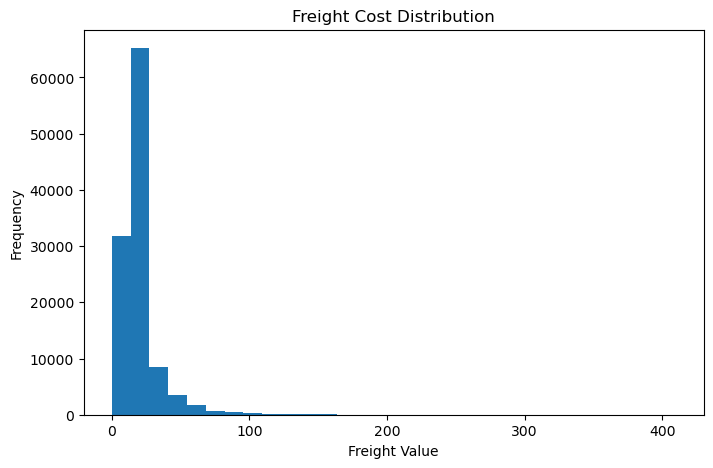

In [67]:
plt.figure(figsize=(8,5))

plt.hist(order_items["freight_value"], bins=30)

plt.title("Freight Cost Distribution")
plt.xlabel("Freight Value")
plt.ylabel("Frequency")

plt.show()

In [68]:
#Average product price
order_items["price"].mean()

np.float64(120.65373901464713)

In [69]:
#Average Freight Cost

order_items["freight_value"].mean()

np.float64(19.990319928983578)

In [70]:
#Minimum Product Price

order_items["price"].min()

0.85

# Merge orders_customers with order_items

In [71]:
orders_full = pd.merge(
    orders_customers,
    order_items,
    on="order_id",
    how="inner"
)

In [72]:
orders_full.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_year,purchase_month,...,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,...,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018,7,...,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018,8,...,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017,11,...,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018,2,...,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72


In [73]:
orders_full.shape

(112650, 23)

In [74]:
orders_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 23 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   order_id                       112650 non-null  object        
 1   customer_id                    112650 non-null  object        
 2   order_status                   112650 non-null  object        
 3   order_purchase_timestamp       112650 non-null  datetime64[ns]
 4   order_approved_at              112635 non-null  datetime64[ns]
 5   order_delivered_carrier_date   111456 non-null  datetime64[ns]
 6   order_delivered_customer_date  110196 non-null  datetime64[ns]
 7   order_estimated_delivery_date  112650 non-null  datetime64[ns]
 8   purchase_year                  112650 non-null  int32         
 9   purchase_month                 112650 non-null  int32         
 10  purchase_day                   112650 non-null  int32         
 11  

In [75]:
# What is the total revenue?

orders_full["price"].sum()

np.float64(13591643.700000001)

In [76]:
# Average Product Price

orders_full["price"].mean()

np.float64(120.65373901464714)

In [77]:
# Total Freight Cost

orders_full["freight_value"].sum()

np.float64(2251909.54)

In [78]:
# Revenue by State

state_revenue = (
    orders_full.groupby("customer_state")["price"]
               .sum()
               .reset_index()
               .sort_values(by="price", ascending=False)
)

state_revenue

,customer_state,price
25,SP,5202955.05
18,RJ,1824092.67
10,MG,1585308.03
22,RS,750304.02
17,PR,683083.76
23,SC,520553.34
4,BA,511349.99
6,DF,302603.94
8,GO,294591.95
7,ES,275037.31


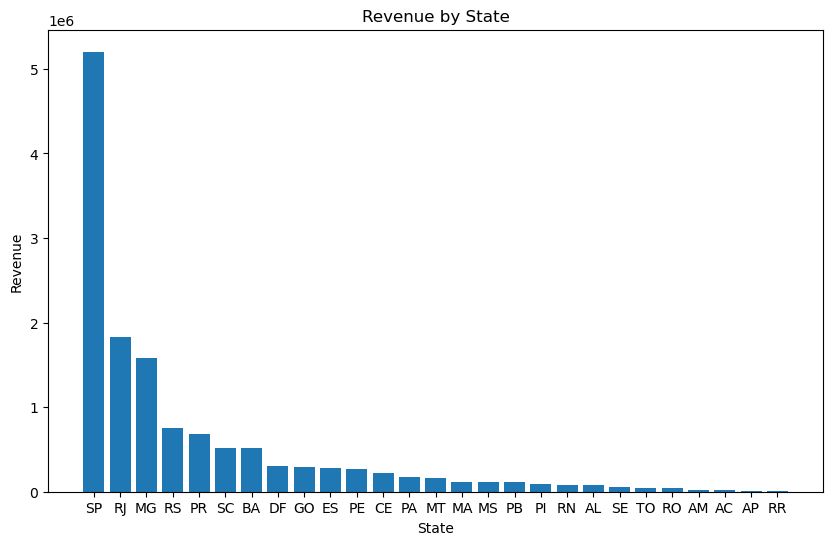

In [79]:
# Visualize Revenue

import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.bar(
    state_revenue["customer_state"],
    state_revenue["price"]
)

plt.title("Revenue by State")
plt.xlabel("State")
plt.ylabel("Revenue")

plt.show()

In [80]:
# Calculate Revenue Per Order

order_value = (
    orders_full.groupby("order_id")["price"]
               .sum()
               .reset_index(name="Order Value")
)

order_value.head()

,order_id,Order Value
0,00010242fe8c5a6d1ba2dd792cb16214,58.90
1,00018f77f2f0320c557190d7a144bdd3,239.90
2,000229ec398224ef6ca0657da4fc703e,199.00
3,00024acbcdf0a6daa1e931b038114c75,12.99
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90


In [81]:
# Calculate Average Order Value

average_order_value = order_value["Order Value"].mean()

print("Average Order Value:", average_order_value)

Average Order Value: 137.75407637889444


In [82]:
# Highest Value Orders

top_orders = (
    order_value.sort_values(
        by="Order Value",
        ascending=False
    )
)

top_orders.head(10)

,order_id,Order Value
1455,03caa2c082116e1d31e67e9ae3700499,13440.0
44467,736e1922ae60d0d6a89247b851902527,7160.0
3130,0812eb902a67711a1cb742b3cdaa65ae,6735.0
98298,fefacc66af859508bf1a7934eab1e97f,6729.0
94439,f5136e38d1a14a4dbd87dff67da82701,6499.0
17114,2cc9089445046817a7539d90805e6e5a,5934.6
65046,a96610ab360d42a2e5335a3998b4718a,4799.0
9868,199af31afc78c699f0dbf71fb178d4d4,4690.0
69531,b4c4b76c642808cbe472a32b86cddc95,4599.9
54353,8dbc85d1447242f3b127dda390d56e19,4590.0


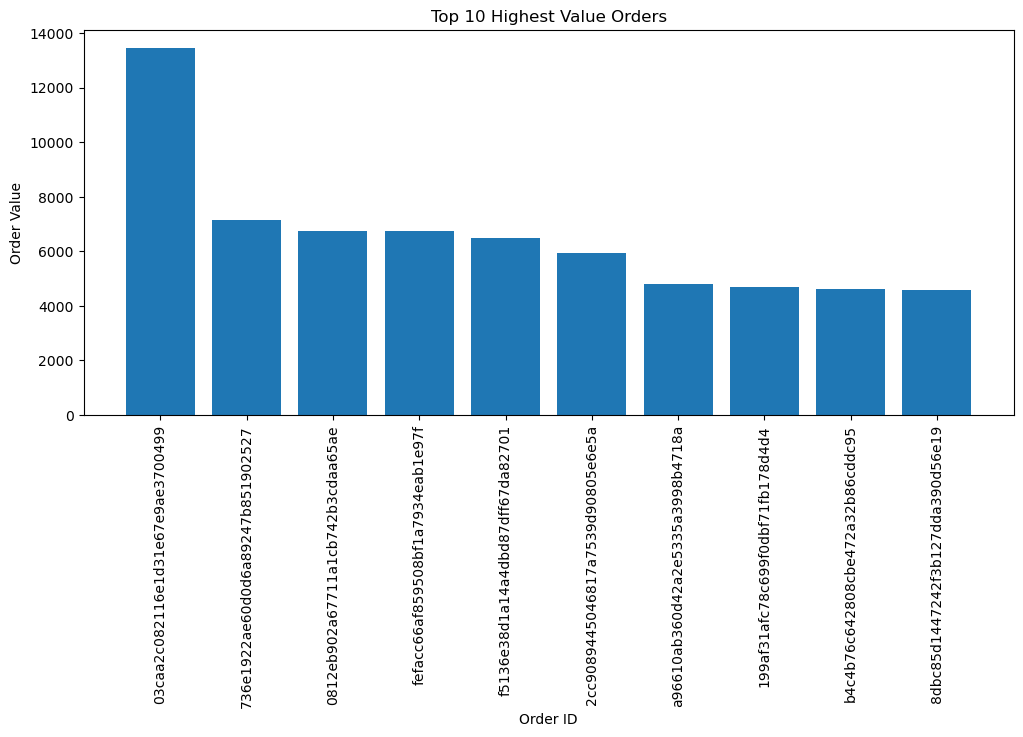

In [83]:
plt.figure(figsize=(12,5))

plt.bar(
    top_orders.head(10)["order_id"],
    top_orders.head(10)["Order Value"]
)

plt.xticks(rotation=90)

plt.title("Top 10 Highest Value Orders")
plt.xlabel("Order ID")
plt.ylabel("Order Value")

plt.show()

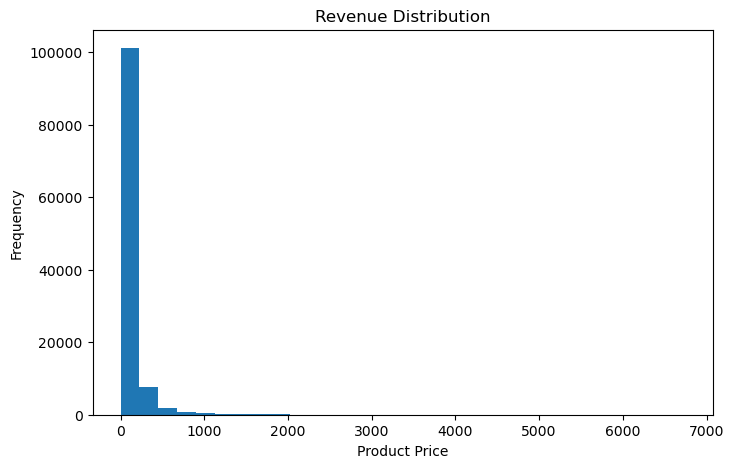

In [84]:
# Revenue Distribution

plt.figure(figsize=(8,5))

plt.hist(
    orders_full["price"],
    bins=30
)

plt.title("Revenue Distribution")
plt.xlabel("Product Price")
plt.ylabel("Frequency")

plt.show()

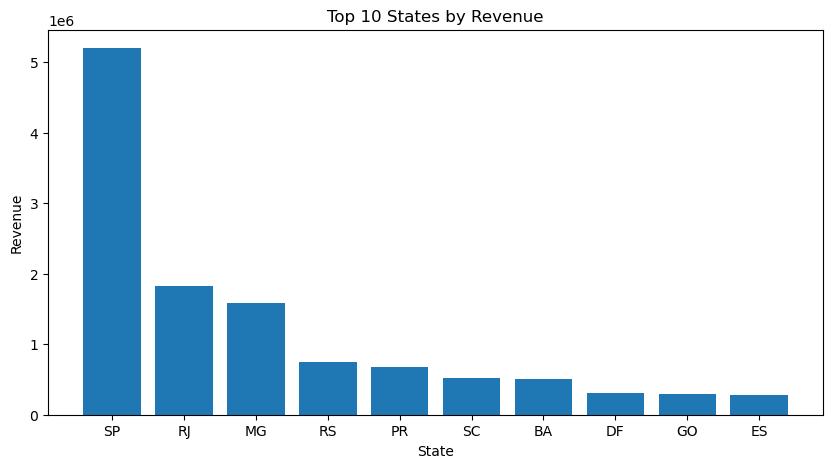

In [85]:
# Top 10 States by Revenue

top10_state_revenue = state_revenue.head(10)

plt.figure(figsize=(10,5))

plt.bar(
    top10_state_revenue["customer_state"],
    top10_state_revenue["price"]
)

plt.title("Top 10 States by Revenue")
plt.xlabel("State")
plt.ylabel("Revenue")

plt.show()

# Product Analysis

In [86]:
# Load the Datasets

products = pd.read_csv("data/raw/olist_products_dataset.csv")

In [87]:
translation = pd.read_csv("data/raw/product_category_name_translation.csv")

In [88]:
# Explore the Products Dataset

In [89]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [90]:
products.shape

(32951, 9)

In [91]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


In [92]:
products.isnull().sum()

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

In [93]:
products.nunique()

product_id                    32951
product_category_name            73
product_name_lenght              66
product_description_lenght     2960
product_photos_qty               19
product_weight_g               2204
product_length_cm                99
product_height_cm               102
product_width_cm                 95
dtype: int64

In [94]:
# Explore the Translation Table

translation.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [95]:
# Merge Products with Translation

products = pd.merge(
    products,
    translation,
    on="product_category_name",
    how="left"
)

In [96]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0,art
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0,baby
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0,housewares


In [97]:
# Merge Products with Your Main Dataset

orders_complete = pd.merge(
    orders_full,
    products,
    on="product_id",
    how="left"
)

In [98]:
orders_complete.shape

(112650, 32)

In [99]:
orders_complete.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_year,purchase_month,...,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,...,8.72,utilidades_domesticas,40.0,268.0,4.0,500.0,19.0,8.0,13.0,housewares
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018,7,...,22.76,perfumaria,29.0,178.0,1.0,400.0,19.0,13.0,19.0,perfumery
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018,8,...,19.22,automotivo,46.0,232.0,1.0,420.0,24.0,19.0,21.0,auto
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017,11,...,27.20,pet_shop,59.0,468.0,3.0,450.0,30.0,10.0,20.0,pet_shop
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018,2,...,8.72,papelaria,38.0,316.0,4.0,250.0,51.0,15.0,15.0,stationery


# First Product Business Question

In [100]:
# Which product categories generate the highest revenue?

category_revenue = (
    orders_complete.groupby("product_category_name_english")["price"]
    .sum()
    .reset_index()
    .sort_values(by="price", ascending=False)
)

category_revenue.head(10)

,product_category_name_english,price
43,health_beauty,1258681.34
70,watches_gifts,1205005.68
7,bed_bath_table,1036988.68
65,sports_leisure,988048.97
15,computers_accessories,911954.32
39,furniture_decor,729762.49
20,cool_stuff,635290.85
49,housewares,632248.66
5,auto,592720.11
42,garden_tools,485256.46


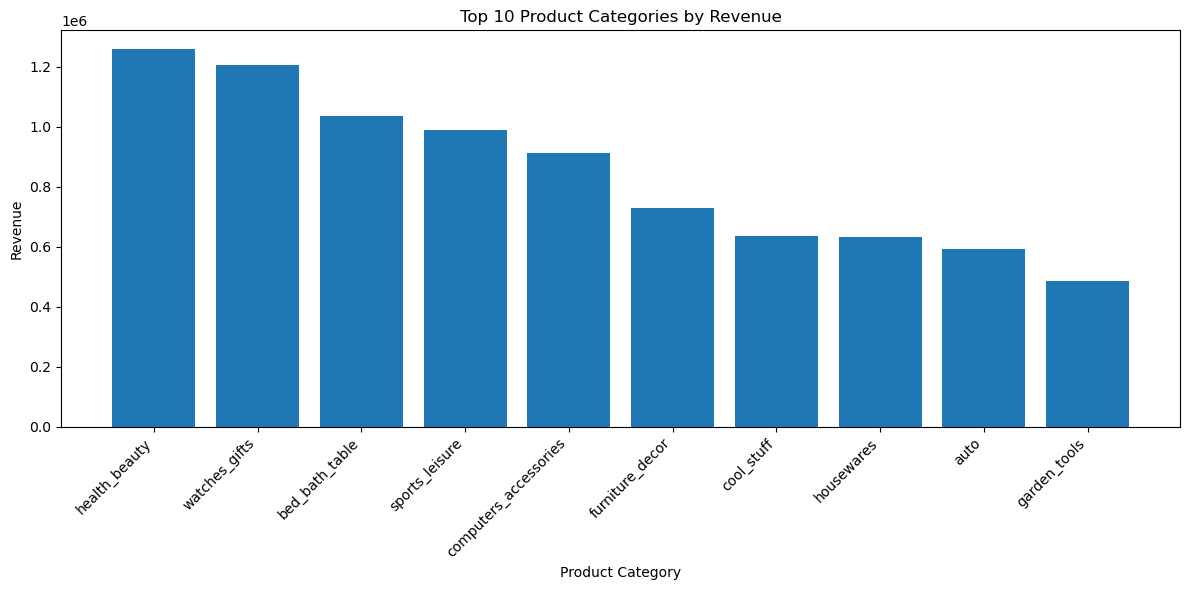

In [101]:
plt.figure(figsize=(12,6))

top10 = category_revenue.head(10)

plt.bar(
    top10["product_category_name_english"],
    top10["price"]
)

plt.xticks(rotation=45, ha="right")

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Product Category")
plt.ylabel("Revenue")

plt.tight_layout()

plt.show()

# Seller Analysis

In [102]:
# Which sellers generate the highest revenue?

In [103]:
# Load the Sellers Dataset

sellers = pd.read_csv("data/raw/olist_sellers_dataset.csv")

In [104]:
sellers.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [105]:
sellers.shape

(3095, 4)

In [106]:
sellers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   seller_id               3095 non-null   object
 1   seller_zip_code_prefix  3095 non-null   int64 
 2   seller_city             3095 non-null   object
 3   seller_state            3095 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.8+ KB


In [107]:
sellers.isnull().sum()

seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64

In [108]:
sellers.nunique()

seller_id                 3095
seller_zip_code_prefix    2246
seller_city                611
seller_state                23
dtype: int64

In [109]:
# Merge Sellers with Main Dataset

orders_final = pd.merge(
    orders_complete,
    sellers,
    on="seller_id",
    how="left"
)

In [110]:
# Verify the Merge

orders_final.shape

(112650, 35)

In [111]:
orders_final.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_year,purchase_month,...,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english,seller_zip_code_prefix,seller_city,seller_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,...,268.0,4.0,500.0,19.0,8.0,13.0,housewares,9350,maua,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018,7,...,178.0,1.0,400.0,19.0,13.0,19.0,perfumery,31570,belo horizonte,SP
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018,8,...,232.0,1.0,420.0,24.0,19.0,21.0,auto,14840,guariba,SP
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017,11,...,468.0,3.0,450.0,30.0,10.0,20.0,pet_shop,31842,belo horizonte,MG
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018,2,...,316.0,4.0,250.0,51.0,15.0,15.0,stationery,8752,mogi das cruzes,SP


In [112]:
# Top 10 Sellers by Revenue

seller_revenue = (
    orders_final.groupby("seller_id")["price"]
    .sum()
    .reset_index()
    .sort_values(by="price", ascending=False)
)

seller_revenue.head(10)

,seller_id,price
857,4869f7a5dfa277a7dca6462dcf3b52b2,229472.63
1013,53243585a1d6dc2643021fd1853d8905,222776.05
881,4a3ca9315b744ce9f8e9374361493884,200472.92
3024,fa1c13f2614d7b5c4749cbc52fecda94,194042.03
1535,7c67e1448b00f6e969d365cea6b010ab,187923.89
1560,7e93a43ef30c4f03f38b393420bc753a,176431.87
2643,da8622b14eb17ae2831f4ac5b9dab84a,160236.57
1505,7a67c85e85bb2ce8582c35f2203ad736,141745.53
192,1025f0e2d44d7041d6cf58b6550e0bfa,138968.55
1824,955fee9216a65b617aa5c0531780ce60,135171.70


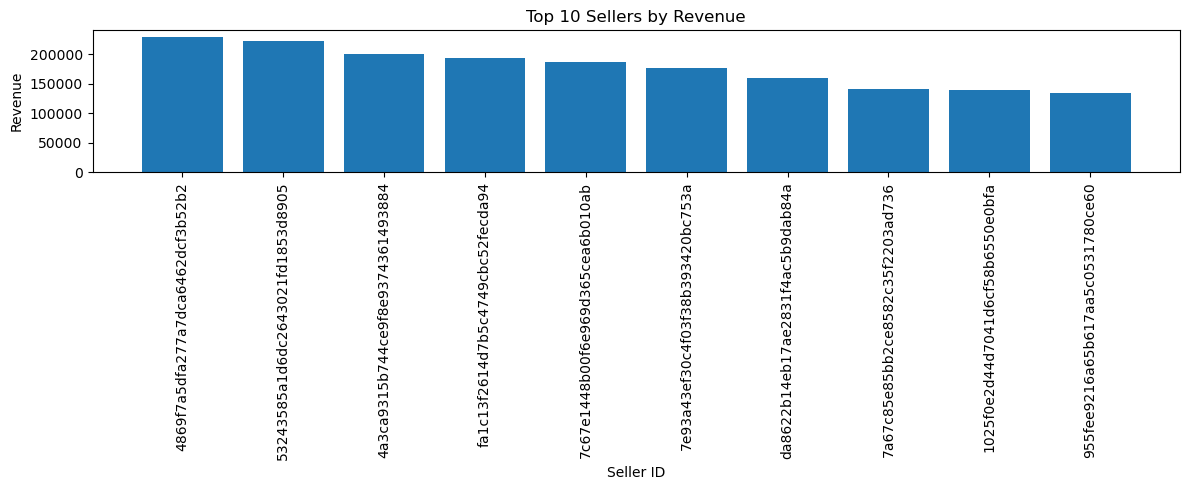

In [113]:
import matplotlib.pyplot as plt

top10_sellers = seller_revenue.head(10)

plt.figure(figsize=(12,5))

plt.bar(
    top10_sellers["seller_id"],
    top10_sellers["price"]
)

plt.xticks(rotation=90)

plt.title("Top 10 Sellers by Revenue")
plt.xlabel("Seller ID")
plt.ylabel("Revenue")

plt.tight_layout()

plt.show()

In [114]:
# Top Seller States

seller_state_revenue = (
    orders_final.groupby("seller_state")["price"]
    .sum()
    .reset_index()
    .sort_values(by="price", ascending=False)
)

seller_state_revenue

,seller_state,price
22,SP,8753396.21
15,PR,1261887.21
8,MG,1011564.74
16,RJ,843984.22
20,SC,632426.07
19,RS,378559.54
2,BA,285561.56
4,DF,97749.48
13,PE,91493.85
6,GO,66399.21


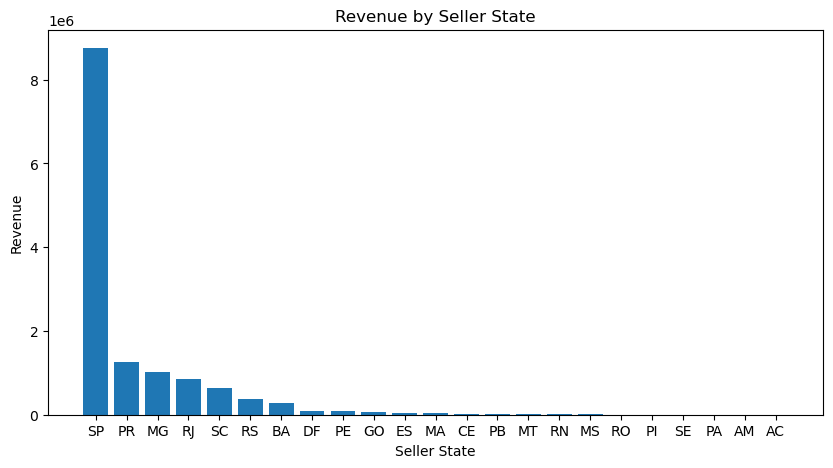

In [115]:
plt.figure(figsize=(10,5))

plt.bar(
    seller_state_revenue["seller_state"],
    seller_state_revenue["price"]
)

plt.title("Revenue by Seller State")
plt.xlabel("Seller State")
plt.ylabel("Revenue")

plt.show()

In [116]:
# Top Seller Cities

seller_city_revenue = (
    orders_final.groupby("seller_city")["price"]
    .sum()
    .reset_index()
    .sort_values(by="price", ascending=False)
)

seller_city_revenue.head(10)

,seller_city,price
517,sao paulo,2702878.14
227,ibitinga,624592.94
159,curitiba,470759.82
450,rio de janeiro,358413.59
220,guarulhos,329494.38
442,ribeirao preto,275976.44
258,itaquaquecetuba,230568.12
218,guariba,229472.63
483,santo andre,228561.60
300,lauro de freitas,225525.05


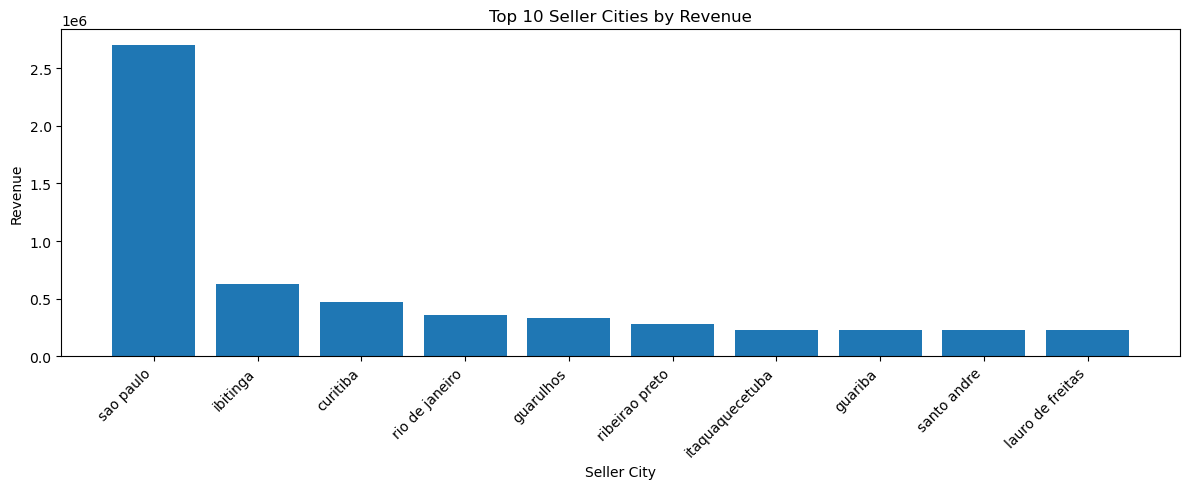

In [117]:
top10_cities = seller_city_revenue.head(10)

plt.figure(figsize=(12,5))

plt.bar(
    top10_cities["seller_city"],
    top10_cities["price"]
)

plt.xticks(rotation=45, ha="right")

plt.title("Top 10 Seller Cities by Revenue")
plt.xlabel("Seller City")
plt.ylabel("Revenue")

plt.tight_layout()

plt.show()

# Payment Analysis

In [118]:
# Load the Payment Dataset

payments = pd.read_csv("data/raw/olist_order_payments_dataset.csv")

In [119]:
payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [120]:
payments.shape

(103886, 5)

In [121]:
payments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB


In [122]:
payments.isnull().sum()

order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

In [123]:
payments.nunique()

order_id                99440
payment_sequential         29
payment_type                5
payment_installments       24
payment_value           29077
dtype: int64

In [124]:
# Merge with Main Dataset

orders_payment = pd.merge(
    orders_final,
    payments,
    on="order_id",
    how="left"
)

In [125]:
# Verify the Merge

orders_payment.shape

(117604, 39)

In [126]:
orders_payment.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_year,purchase_month,...,product_height_cm,product_width_cm,product_category_name_english,seller_zip_code_prefix,seller_city,seller_state,payment_sequential,payment_type,payment_installments,payment_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,...,8.0,13.0,housewares,9350,maua,SP,1.0,credit_card,1.0,18.12
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,...,8.0,13.0,housewares,9350,maua,SP,3.0,voucher,1.0,2.00
2,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,...,8.0,13.0,housewares,9350,maua,SP,2.0,voucher,1.0,18.59
3,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018,7,...,13.0,19.0,perfumery,31570,belo horizonte,SP,1.0,boleto,1.0,141.46
4,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018,8,...,19.0,21.0,auto,14840,guariba,SP,1.0,credit_card,3.0,179.12


# Which payment method is most popular?

In [127]:
payment_method = (
    orders_payment.groupby("payment_type")
    .size()
    .reset_index(name="Number of Payments")
    .sort_values(by="Number of Payments", ascending=False)
)

payment_method

,payment_type,Number of Payments
1,credit_card,86769
0,boleto,22867
3,voucher,6274
2,debit_card,1691


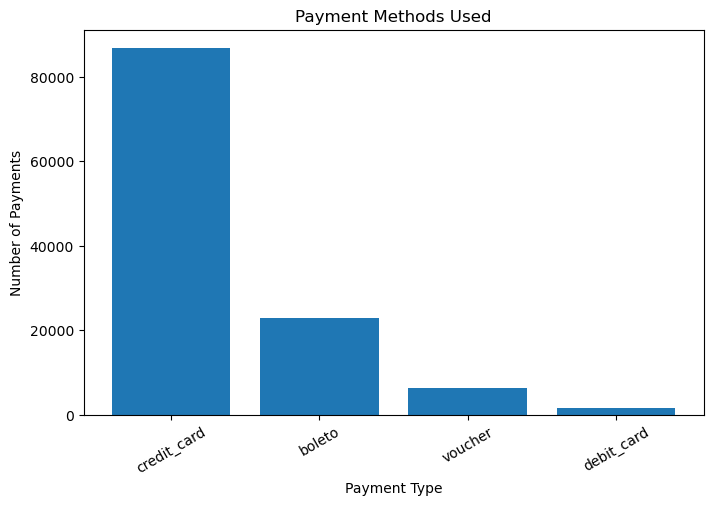

In [128]:
plt.figure(figsize=(8,5))

plt.bar(
    payment_method["payment_type"],
    payment_method["Number of Payments"]
)

plt.title("Payment Methods Used")
plt.xlabel("Payment Type")
plt.ylabel("Number of Payments")

plt.xticks(rotation=30)

plt.show()

# Revenue by Payment Method

In [129]:
payment_revenue = (
    orders_payment.groupby("payment_type")["payment_value"]
    .sum()
    .reset_index()
    .sort_values(by="payment_value", ascending=False)
)

payment_revenue

,payment_type,payment_value
1,credit_card,15589028.22
0,boleto,4059699.60
3,voucher,405873.03
2,debit_card,253533.86


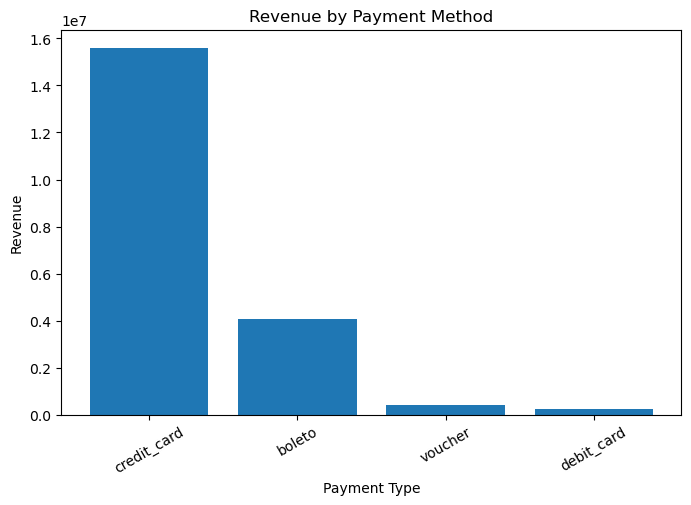

In [130]:
plt.figure(figsize=(8,5))

plt.bar(
    payment_revenue["payment_type"],
    payment_revenue["payment_value"]
)

plt.title("Revenue by Payment Method")
plt.xlabel("Payment Type")
plt.ylabel("Revenue")

plt.xticks(rotation=30)

plt.show()

# Average Payment Value

In [131]:
payments["payment_value"].mean()

np.float64(154.10038041699556)

# Installment Analysis

In [132]:
installments = (
    payments.groupby("payment_installments")
    .size()
    .reset_index(name="Number of Orders")
)

installments

,payment_installments,Number of Orders
0,0,2
1,1,52546
2,2,12413
3,3,10461
4,4,7098
5,5,5239
6,6,3920
7,7,1626
8,8,4268
9,9,644


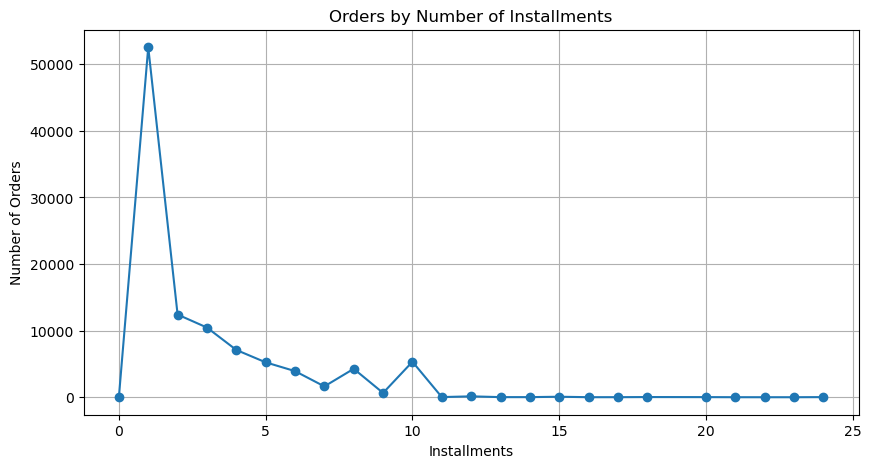

In [133]:
plt.figure(figsize=(10,5))

plt.plot(
    installments["payment_installments"],
    installments["Number of Orders"],
    marker="o"
)

plt.title("Orders by Number of Installments")
plt.xlabel("Installments")
plt.ylabel("Number of Orders")

plt.grid(True)

plt.show()

# Customer Review Analysis

In [134]:
# Load the Review Dataset

reviews = pd.read_csv("data/raw/olist_order_reviews_dataset.csv")

In [135]:
reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [136]:
reviews.shape

(99224, 7)

In [137]:
reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [138]:
reviews.isnull().sum()

review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

In [139]:
reviews.nunique()

review_id                  98410
order_id                   98673
review_score                   5
review_comment_title        4527
review_comment_message     36159
review_creation_date         636
review_answer_timestamp    98248
dtype: int64

# Average Review Score

In [140]:
reviews["review_score"].mean()

np.float64(4.08642062404257)

# Review Score Distribution

In [141]:
review_distribution = (
    reviews.groupby("review_score")
           .size()
           .reset_index(name="Number of Reviews")
)

review_distribution

,review_score,Number of Reviews
0,1,11424
1,2,3151
2,3,8179
3,4,19142
4,5,57328


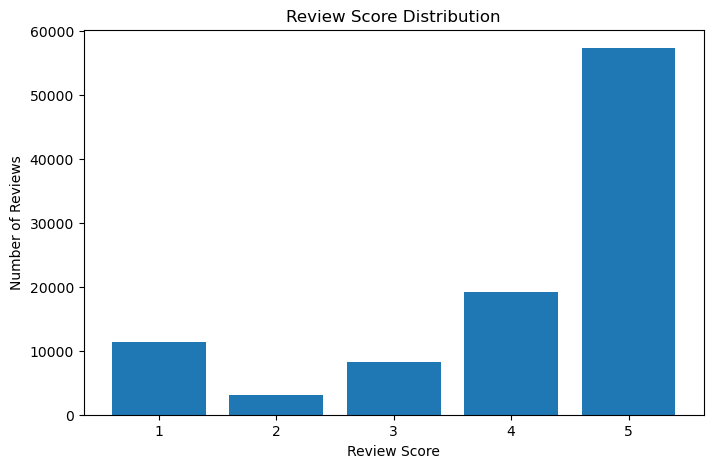

In [142]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.bar(
    review_distribution["review_score"],
    review_distribution["Number of Reviews"]
)

plt.title("Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")

plt.show()

# Percentage of Each Rating

In [143]:
review_percentage = (
    reviews["review_score"]
           .value_counts(normalize=True)
           .sort_index() * 100
)

review_percentage

review_score
1    11.513344
2     3.175643
3     8.242965
4    19.291704
5    57.776344
Name: proportion, dtype: float64

# Does faster delivery lead to better customer ratings?

# Calculate Delivery Time

In [144]:
orders_payment.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_year,purchase_month,...,product_height_cm,product_width_cm,product_category_name_english,seller_zip_code_prefix,seller_city,seller_state,payment_sequential,payment_type,payment_installments,payment_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,...,8.0,13.0,housewares,9350,maua,SP,1.0,credit_card,1.0,18.12
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,...,8.0,13.0,housewares,9350,maua,SP,3.0,voucher,1.0,2.00
2,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,...,8.0,13.0,housewares,9350,maua,SP,2.0,voucher,1.0,18.59
3,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018,7,...,13.0,19.0,perfumery,31570,belo horizonte,SP,1.0,boleto,1.0,141.46
4,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018,8,...,19.0,21.0,auto,14840,guariba,SP,1.0,credit_card,3.0,179.12


In [145]:
orders_reviews = pd.merge(
    orders_payment,
    reviews,
    on="order_id",
    how="left"
)

In [146]:
orders_reviews["delivery_days"] = (
    orders_reviews["order_delivered_customer_date"]
    - orders_reviews["order_purchase_timestamp"]
).dt.days

# Check the New Column

In [147]:
orders_reviews[[
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "delivery_days"
]].head()

,order_purchase_timestamp,order_delivered_customer_date,delivery_days
0,2017-10-02 10:56:33,2017-10-10 21:25:13,8.0
1,2017-10-02 10:56:33,2017-10-10 21:25:13,8.0
2,2017-10-02 10:56:33,2017-10-10 21:25:13,8.0
3,2018-07-24 20:41:37,2018-08-07 15:27:45,13.0
4,2018-08-08 08:38:49,2018-08-17 18:06:29,9.0


In [148]:
delivery_reviews = (
    orders_reviews.groupby("review_score")["delivery_days"]
                  .mean()
                  .reset_index()
)

delivery_reviews

,review_score,delivery_days
0,1.0,19.099992
1,2.0,15.381893
2,3.0,13.552435
3,4.0,11.778330
4,5.0,10.203253


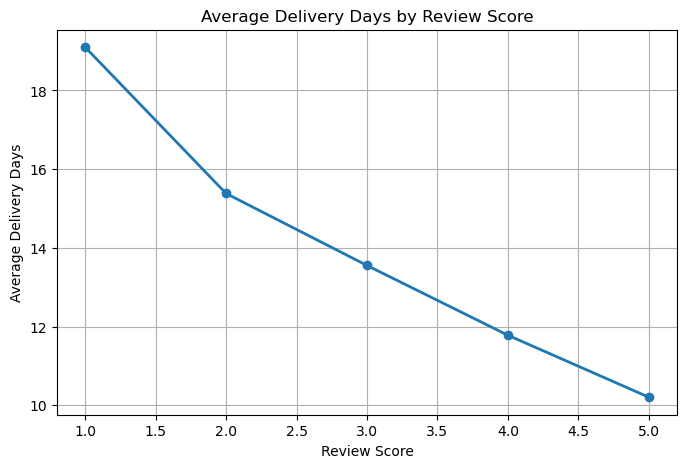

In [149]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    delivery_reviews["review_score"],
    delivery_reviews["delivery_days"],
    marker="o",
    linewidth=2
)

plt.title("Average Delivery Days by Review Score")
plt.xlabel("Review Score")
plt.ylabel("Average Delivery Days")

plt.grid(True)

plt.show()

# Calculate Delivery Delay

In [150]:
orders_reviews["delivery_delay"] = (
    orders_reviews["order_delivered_customer_date"]
    - orders_reviews["order_estimated_delivery_date"]
).dt.days

# Average Delay by Rating

In [151]:
delay_reviews = (
    orders_reviews.groupby("review_score")["delivery_delay"]
                  .mean()
                  .reset_index()
)

delay_reviews

,review_score,delivery_delay
0,1.0,-5.993827
1,2.0,-9.748141
2,3.0,-11.114301
3,4.0,-12.468533
4,5.0,-13.443437


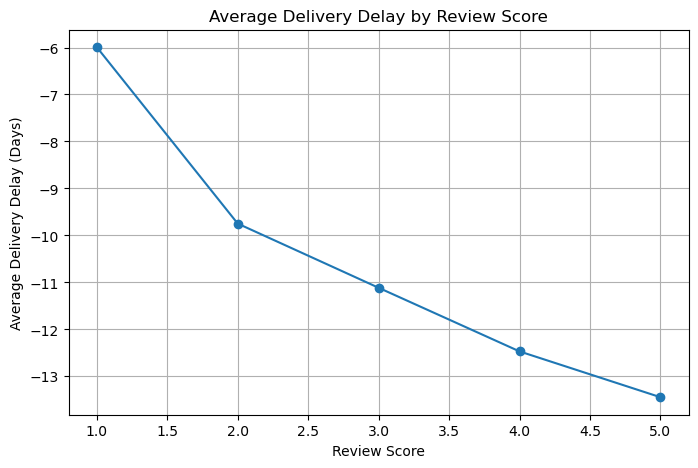

In [152]:
plt.figure(figsize=(8,5))

plt.plot(
    delay_reviews["review_score"],
    delay_reviews["delivery_delay"],
    marker="o"
)

plt.title("Average Delivery Delay by Review Score")
plt.xlabel("Review Score")
plt.ylabel("Average Delivery Delay (Days)")

plt.grid(True)

plt.show()

# SQL Analysis

### Use SQLite in Jupyter

In [153]:
import sqlite3
import pandas as pd

In [154]:
# Create a database connection:

conn = sqlite3.connect("olist.db")

In [155]:
# Load Data into SQL Tables

orders.to_sql("orders", conn, if_exists="replace", index=False)
customers.to_sql("customers", conn, if_exists="replace", index=False)
order_items.to_sql("order_items", conn, if_exists="replace", index=False)
products.to_sql("products", conn, if_exists="replace", index=False)
sellers.to_sql("sellers", conn, if_exists="replace", index=False)
payments.to_sql("payments", conn, if_exists="replace", index=False)
reviews.to_sql("reviews", conn, if_exists="replace", index=False)

99224

In [156]:
# Verify the Tables

query = "SELECT name FROM sqlite_master WHERE type='table';"
pd.read_sql(query, conn)

,name
0,orders
1,customers
2,order_items
3,products
4,sellers
5,payments
6,reviews


# Total Orders

In [157]:
query = """
SELECT COUNT(*) AS total_orders
FROM orders;
"""

pd.read_sql(query, conn)

,total_orders
0,99441


# Orders by Status

In [158]:
query = """
SELECT order_status,
       COUNT(*) AS total_orders
FROM orders
GROUP BY order_status
ORDER BY total_orders DESC;
"""

pd.read_sql(query, conn)

,order_status,total_orders
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


# Top 10 States by Customers

In [159]:
query = """
SELECT customer_state,
       COUNT(*) AS total_customers
FROM customers
GROUP BY customer_state
ORDER BY total_customers DESC
LIMIT 10;
"""

pd.read_sql(query, conn)

,customer_state,total_customers
0,SP,41746
1,RJ,12852
2,MG,11635
3,RS,5466
4,PR,5045
5,SC,3637
6,BA,3380
7,DF,2140
8,ES,2033
9,GO,2020


# Total Revenue

In [160]:
query = """
SELECT ROUND(SUM(price), 2) AS total_revenue
FROM order_items;
"""

pd.read_sql(query, conn)

,total_revenue
0,13591643.7


# Average Product Price

In [161]:
query = """
SELECT ROUND(AVG(price), 2) AS average_price
FROM order_items;
"""

pd.read_sql(query, conn)

,average_price
0,120.65


# SQL JOIN Analysis

# Revenue by Customer State

In [162]:
query = """
SELECT c.customer_state,
       ROUND(SUM(oi.price), 2) AS total_revenue
FROM orders o
JOIN customers c
ON o.customer_id = c.customer_id
JOIN order_items oi
ON o.order_id = oi.order_id
GROUP BY c.customer_state
ORDER BY total_revenue DESC;
"""

pd.read_sql(query, conn)

,customer_state,total_revenue
0,SP,5202955.05
1,RJ,1824092.67
2,MG,1585308.03
3,RS,750304.02
4,PR,683083.76
5,SC,520553.34
6,BA,511349.99
7,DF,302603.94
8,GO,294591.95
9,ES,275037.31


# Top 10 Customers by Spending

In [163]:
query = """
SELECT c.customer_unique_id,
       ROUND(SUM(oi.price), 2) AS total_spent
FROM orders o
JOIN customers c
ON o.customer_id = c.customer_id
JOIN order_items oi
ON o.order_id = oi.order_id
GROUP BY c.customer_unique_id
ORDER BY total_spent DESC
LIMIT 10;
"""

pd.read_sql(query, conn)

,customer_unique_id,total_spent
0,0a0a92112bd4c708ca5fde585afaa872,13440.0
1,da122df9eeddfedc1dc1f5349a1a690c,7388.0
2,763c8b1c9c68a0229c42c9fc6f662b93,7160.0
3,dc4802a71eae9be1dd28f5d788ceb526,6735.0
4,459bef486812aa25204be022145caa62,6729.0
5,ff4159b92c40ebe40454e3e6a7c35ed6,6499.0
6,4007669dec559734d6f53e029e360987,5934.6
7,eebb5dda148d3893cdaf5b5ca3040ccb,4690.0
8,5d0a2980b292d049061542014e8960bf,4599.9
9,48e1ac109decbb87765a3eade6854098,4590.0


# Top Product Categories by Revenue

In [164]:
query = """
SELECT p.product_category_name,
       ROUND(SUM(oi.price), 2) AS total_revenue
FROM order_items oi
JOIN products p
ON oi.product_id = p.product_id
GROUP BY p.product_category_name
ORDER BY total_revenue DESC
LIMIT 10;
"""

pd.read_sql(query, conn)

,product_category_name,total_revenue
0,beleza_saude,1258681.34
1,relogios_presentes,1205005.68
2,cama_mesa_banho,1036988.68
3,esporte_lazer,988048.97
4,informatica_acessorios,911954.32
5,moveis_decoracao,729762.49
6,cool_stuff,635290.85
7,utilidades_domesticas,632248.66
8,automotivo,592720.11
9,ferramentas_jardim,485256.46


# Top Sellers by Revenue

In [165]:
query = """
SELECT s.seller_id,
       ROUND(SUM(oi.price), 2) AS total_revenue
FROM order_items oi
JOIN sellers s
ON oi.seller_id = s.seller_id
GROUP BY s.seller_id
ORDER BY total_revenue DESC
LIMIT 10;
"""

pd.read_sql(query, conn)

,seller_id,total_revenue
0,4869f7a5dfa277a7dca6462dcf3b52b2,229472.63
1,53243585a1d6dc2643021fd1853d8905,222776.05
2,4a3ca9315b744ce9f8e9374361493884,200472.92
3,fa1c13f2614d7b5c4749cbc52fecda94,194042.03
4,7c67e1448b00f6e969d365cea6b010ab,187923.89
5,7e93a43ef30c4f03f38b393420bc753a,176431.87
6,da8622b14eb17ae2831f4ac5b9dab84a,160236.57
7,7a67c85e85bb2ce8582c35f2203ad736,141745.53
8,1025f0e2d44d7041d6cf58b6550e0bfa,138968.55
9,955fee9216a65b617aa5c0531780ce60,135171.70


# Average Order Value

In [166]:
query = """
SELECT ROUND(AVG(order_total), 2) AS average_order_value
FROM (
    SELECT order_id,
           SUM(price) AS order_total
    FROM order_items
    GROUP BY order_id
);
"""

pd.read_sql(query, conn)

,average_order_value
0,137.75


# Advanced SQL Analysis

## Second highest revenue state

In [167]:
# Using LIMIT

query = """
SELECT c.customer_state,
       ROUND(SUM(oi.price), 2) AS total_revenue
FROM orders o
JOIN customers c
ON o.customer_id = c.customer_id
JOIN order_items oi
ON o.order_id = oi.order_id
GROUP BY c.customer_state
ORDER BY total_revenue DESC
LIMIT 1 OFFSET 1;
"""

pd.read_sql(query, conn)

,customer_state,total_revenue
0,RJ,1824092.67


## Monthly revenue trend

In [168]:
query = """
SELECT strftime('%Y-%m', o.order_purchase_timestamp) AS month,
       ROUND(SUM(oi.price), 2) AS total_revenue
FROM orders o
JOIN order_items oi
ON o.order_id = oi.order_id
GROUP BY month
ORDER BY month;
"""

monthly_revenue = pd.read_sql(query, conn)

monthly_revenue.head()

,month,total_revenue
0,2016-09,267.36
1,2016-10,49507.66
2,2016-12,10.90
3,2017-01,120312.87
4,2017-02,247303.02


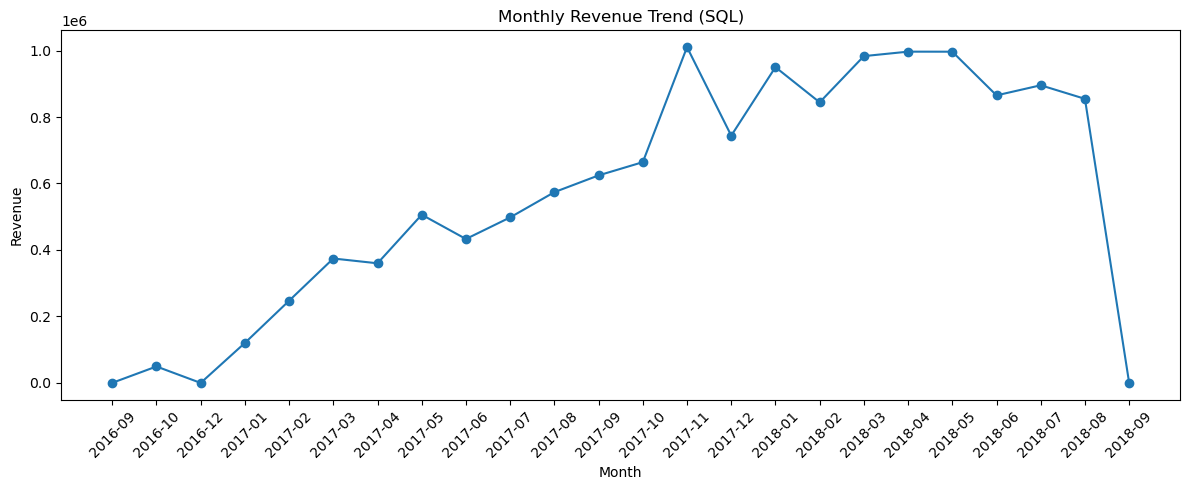

In [169]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.plot(monthly_revenue["month"], monthly_revenue["total_revenue"], marker="o")

plt.xticks(rotation=45)
plt.title("Monthly Revenue Trend (SQL)")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.tight_layout()
plt.show()

# Repeat customers

## How many customers placed more than one order?

In [170]:
query = """
SELECT c.customer_unique_id,
       COUNT(o.order_id) AS total_orders
FROM customers c
JOIN orders o
ON c.customer_id = o.customer_id
GROUP BY c.customer_unique_id
HAVING COUNT(o.order_id) > 1
ORDER BY total_orders DESC;
"""

repeat_customers = pd.read_sql(query, conn)

repeat_customers.head()

,customer_unique_id,total_orders
0,8d50f5eadf50201ccdcedfb9e2ac8455,17
1,3e43e6105506432c953e165fb2acf44c,9
2,ca77025e7201e3b30c44b472ff346268,7
3,6469f99c1f9dfae7733b25662e7f1782,7
4,1b6c7548a2a1f9037c1fd3ddfed95f33,7


# Count of repeat customers

In [171]:
query = """
SELECT COUNT(*) AS repeat_customer_count
FROM (
    SELECT c.customer_unique_id
    FROM customers c
    JOIN orders o
    ON c.customer_id = o.customer_id
    GROUP BY c.customer_unique_id
    HAVING COUNT(o.order_id) > 1
);
"""

pd.read_sql(query, conn)

,repeat_customer_count
0,2997


# Rank states by revenue

In [172]:
query = """
SELECT customer_state,
       total_revenue,
       RANK() OVER (ORDER BY total_revenue DESC) AS revenue_rank
FROM (
    SELECT c.customer_state,
           ROUND(SUM(oi.price), 2) AS total_revenue
    FROM orders o
    JOIN customers c
    ON o.customer_id = c.customer_id
    JOIN order_items oi
    ON o.order_id = oi.order_id
    GROUP BY c.customer_state
);
"""

pd.read_sql(query, conn)

,customer_state,total_revenue,revenue_rank
0,SP,5202955.05,1
1,RJ,1824092.67,2
2,MG,1585308.03,3
3,RS,750304.02,4
4,PR,683083.76,5
5,SC,520553.34,6
6,BA,511349.99,7
7,DF,302603.94,8
8,GO,294591.95,9
9,ES,275037.31,10


# Dense rank

In [173]:
query = """
SELECT customer_state,
       total_revenue,
       DENSE_RANK() OVER (ORDER BY total_revenue DESC) AS revenue_rank
FROM (
    SELECT c.customer_state,
           ROUND(SUM(oi.price), 2) AS total_revenue
    FROM orders o
    JOIN customers c
    ON o.customer_id = c.customer_id
    JOIN order_items oi
    ON o.order_id = oi.order_id
    GROUP BY c.customer_state
);
"""

pd.read_sql(query, conn)

,customer_state,total_revenue,revenue_rank
0,SP,5202955.05,1
1,RJ,1824092.67,2
2,MG,1585308.03,3
3,RS,750304.02,4
4,PR,683083.76,5
5,SC,520553.34,6
6,BA,511349.99,7
7,DF,302603.94,8
8,GO,294591.95,9
9,ES,275037.31,10


# Export the final dataset from Python

In [174]:
orders_reviews.to_csv("data/cleaned/olist_final_dataset.csv", index=False) 